# TRABAJO DE INVESTIGACIÓN DE OPERACIONES 1
## OPTIMIZACIÓN DE PERSONAL Y SIMULACIÓN DE EVENTOS DISCRETOS — DISTRIBUIDORA "DENLU"

**Estudio de caso:** distribuidora mayorista DENLU (Tarma, Junín).
**Metodología:** teoría de colas $M/M/c$, programación lineal entera mixta (MILP) con turnos bajo el D.S. 003-97-TR y simulación de eventos discretos construida sobre los datos reales de 2025.

Este cuaderno es **un solo flujo de trabajo**: lo que se calcula en la Parte I (tasas de llegada, requerimiento por hora, plan óptimo, costos y las causas de la venta perdida) es exactamente lo que usa la simulación de la Parte II. No hay constantes copiadas de un cuaderno a otro.

| Parte | Capítulo | Pregunta que responde |
|---|---|---|
| **I. Diagnóstico y optimización** | 1. Diagnóstico (colas) | ¿Dónde se congestiona hoy el almacén? |
| | 2. Causas de la venta perdida | ¿Cuánto de lo que se pierde depende del despacho? |
| | 3–4. Modelo MILP y solución | ¿Cuántos despachadores y en qué turnos? |
| | 5. ROI analítico | ¿Qué ganaría el plan si todo lo perdido fuera recuperable? |
| **II. Simulación** | 6–7. Modelo y validación | ¿El modelo reproduce el almacén real? |
| | 8. Plan actual vs. MILP | ¿Qué cambia de verdad con más personal? |
| | 9–10. Demanda y ausentismo | ¿Qué tan robusto es? |
| | 11. $\rho$ objetivo y margen bruto | ¿Conviene otro nivel de servicio? |
| | 12. ¿Personal o quiebres de stock? | ¿Dónde está el dinero? |
| | 13. Conclusiones | Resumen calculado con los resultados de arriba |

**Datos.** Si el archivo `denlu_colab_2025.csv` está junto al cuaderno (en Colab: panel de archivos → subir), se usa completo y el capítulo 7 repite los 8 012 pedidos reales por el simulador. Si no, el cuaderno parte de los parámetros que se estimaron de ese archivo y todo lo demás se calcula igual.

**Simulador interactivo** (animación de un día y comparación del año completo): <https://efustion23.github.io/denlu-simulacion/>

# PARTE I — DIAGNÓSTICO Y OPTIMIZACIÓN

## 1. Diagnóstico de la situación actual (teoría de colas)

La distribuidora **DENLU** comercializa productos de primera necesidad en la región de Tarma. Su almacén opera con **3 despachadores fijos**. Los pedidos se preparan en orden de llegada y salen en tres camiones a horas fijas (10:00, 13:00 y 16:00); un pedido pierde su camión si no está listo a tiempo.

A continuación se diagnostica la tasa de llegada ($\lambda_h$), la utilización del sistema ($\rho_h$), el tiempo promedio de espera y la pérdida de ruta por hora de la operación actual.

In [1]:
%pip install -q --disable-pip-version-check simpy ortools

import json
from collections import namedtuple
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import simpy
from ortools.linear_solver import pywraplp

# Paleta compartida con el simulador web: azul acero = plan elegido, gris = situación actual
COLOR = {"plan": "#2d5c88", "actual": "#a3a7a4", "hist": "#c19463", "alerta": "#c4242a", "ok": "#1e7b4f",
         "aviso": "#f2b705", "tinta": "#141617", "tinta2": "#5b5f5c", "linea": "#e3e5e1"}
COLOR_CAUSA = {"quiebre": COLOR["aviso"], "calendario": COLOR["hist"], "despacho": COLOR["plan"]}
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": COLOR["linea"], "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelcolor": COLOR["tinta2"], "xtick.color": COLOR["tinta2"], "ytick.color": COLOR["tinta2"],
    "text.color": COLOR["tinta"], "legend.frameon": False, "font.size": 10.5,
})
soles = lambda v: f"S/ {v:,.0f}" if v >= 0 else f"−S/ {-v:,.0f}"
k_soles = lambda v, _=None: f"{v / 1000:,.0f} mil"

Note: you may need to restart the kernel to use updated packages.


In [2]:
def estimar_parametros(df):
    # Todo lo que la simulación necesita saber de los datos de 2025
    H = list(range(8, 18))
    n = len(df)
    dias = df["fecha"].nunique()
    sin_q = df[df["quiebre_stock"] == 0]
    q = df[df["quiebre_stock"] == 1]
    tarde = lambda d: d["hora_del_dia"] >= 15                      # llegan cuando ya no sale camión ese día
    procesados = df[df["cancelado"] == 0]["tiempo_preparacion_min"]
    por_dia = df.groupby("fecha").agg(n=("id_pedido", "size"), d=("dia_semana", "first")).groupby("d")["n"].mean()
    orden = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado"]
    c, cp = df[df["cancelado"] == 1], df[df["cliente_perdido"] == 1]
    e = df[df["salida_ruta"] != "Sin entrega"]
    transito = (pd.to_datetime(e["entrega_fecha_hora"]) - pd.to_datetime(e["salida_ruta"])).dt.total_seconds() / 3600
    por_hora = lambda col, f=1.0: [round(f * df[df["hora_del_dia"] == h][col].mean(), 2) for h in H]
    return {
        "pedidos": n, "dias": dias, "dias_refuerzo": int(df[df["n_despachadores"] == 4]["fecha"].nunique()),
        "lambda": [round(len(df[df["hora_del_dia"] == h]) / dias, 3) for h in H],
        "factor_dia": [round(por_dia[d] / (n / dias), 3) for d in orden],
        "espera_h": por_hora("tiempo_espera_min"), "perdio_ruta_h": por_hora("perdio_ruta", 100), "cancelado_h": por_hora("cancelado", 100),
        "servicio_sd": round(procesados.std(), 2), "servicio_media": round(procesados.mean(), 2),
        "p_quiebre": round(len(q) / n, 4),
        "cancel_quiebre_temprano": [round(q[(q["dias_reposicion"] == d) & ~tarde(q)]["cancelado"].mean(), 3) for d in (1, 2, 3, 4)],
        "cancel_quiebre_tarde": [round(q[(q["dias_reposicion"] == d) & tarde(q)]["cancelado"].mean(), 3) for d in (1, 2, 3, 4)],
        "cancel_sin_quiebre_tarde": round(sin_q[tarde(sin_q)]["cancelado"].mean(), 4),
        "p_cliente_perdido": round(df[df["entrega_tardia"] == 1]["cliente_perdido"].mean(), 4),
        "monto_media": round(df["monto_pedido_S"].mean(), 1), "monto_sd": round(df["monto_pedido_S"].std(), 1),
        "transito_h": [round(transito.min(), 2), round(transito.max(), 2)],
        "perdio_ruta_pct": round(100 * df["perdio_ruta"].mean(), 2), "tardia_pct": round(100 * df["entrega_tardia"].mean(), 2),
        "cancelado_pct": round(100 * df["cancelado"].mean(), 2), "cliente_perdido_pct": round(100 * df["cliente_perdido"].mean(), 2),
        "espera_media": round(df["tiempo_espera_min"].mean(), 2),
        "venta_perdida": round(float(df["venta_perdida_S"].sum()), 2), "cancelados": int(df["cancelado"].sum()),
        # venta perdida por causa: (pedidos, soles)
        "causas": {
            "Cancelación con quiebre de stock": (int((c["quiebre_stock"] == 1).sum()), round(float(c[c["quiebre_stock"] == 1]["venta_perdida_S"].sum()), 2), "quiebre"),
            "Cliente perdido tras entrega tardía por quiebre de stock": (int((cp["quiebre_stock"] == 1).sum()), round(float(cp[cp["quiebre_stock"] == 1]["venta_perdida_S"].sum()), 2), "quiebre"),
            "Cancelación sin quiebre (el pedido llega después de las 15 h)": (int((c["quiebre_stock"] == 0).sum()), round(float(c[c["quiebre_stock"] == 0]["venta_perdida_S"].sum()), 2), "calendario"),
            "Cliente perdido por calendario (sábado o pedido de fin de día)": (int(((cp["quiebre_stock"] == 0) & (cp["perdio_ruta"] == 0)).sum()), round(float(cp[(cp["quiebre_stock"] == 0) & (cp["perdio_ruta"] == 0)]["venta_perdida_S"].sum()), 2), "calendario"),
            "Cliente perdido tras perder la ruta (despacho)": (int(((cp["quiebre_stock"] == 0) & (cp["perdio_ruta"] == 1)).sum()), round(float(cp[(cp["quiebre_stock"] == 0) & (cp["perdio_ruta"] == 1)]["venta_perdida_S"].sum()), 2), "despacho"),
        },
    }

In [3]:
RUTA_CSV = Path("denlu_colab_2025.csv")      # opcional; sin él se usan los parámetros ya estimados de abajo

# Parámetros del sistema actual
MU_MIN = 44.5                                # tiempo medio de preparación de un pedido (min), de los datos de 2025
MU_H = 60.0 / MU_MIN                         # tasa de servicio individual (~1.348 ped/h)
C_ACTUAL = 3                                 # despachadores fijos hoy
DIAS = 299                                   # días operativos por año
HORAS = list(range(8, 18))

# Resultado de estimar_parametros() con el CSV completo de 2025 (8 012 pedidos)
PARAMETROS_2025 = {'pedidos': 8012,
 'dias': 299,
 'dias_refuerzo': 24,
 'lambda': [1.783, 3.575, 3.853, 3.351, 1.89, 1.458, 3.023, 3.495, 2.545, 1.823],
 'factor_dia': [1.116, 0.962, 0.997, 1.004, 1.096, 0.819],
 'espera_h': [1.4, 7.33, 15.56, 20.49, 14.07, 7.78, 7.99, 11.19, 12.99, 7.34],
 'perdio_ruta_h': [1.31, 4.68, 2.17, 15.67, 8.85, 0.0, 7.52, 6.22, 0.0, 0.0],
 'cancelado_h': [3.19, 4.12, 4.77, 4.69, 3.19, 3.9, 3.98, 10.43, 9.33, 9.54],
 'servicio_sd': 17.87,
 'servicio_media': 44.47,
 'p_quiebre': 0.1033,
 'cancel_quiebre_temprano': [0.082, 0.331, 0.51, 0.733],
 'cancel_quiebre_tarde': [0.204, 0.41, 0.579, 0.833],
 'cancel_sin_quiebre_tarde': 0.0533,
 'p_cliente_perdido': 0.1608,
 'monto_media': 2475.0,
 'monto_sd': 1414.0,
 'transito_h': [0.33, 1.98],
 'perdio_ruta_pct': 5.27,
 'tardia_pct': 8.92,
 'cancelado_pct': 5.82,
 'cliente_perdido_pct': 1.44,
 'espera_media': 11.38,
 'venta_perdida': 1820720.93,
 'cancelados': 466,
 'causas': {'Cancelación con quiebre de stock': (353, 917940.25, 'quiebre'),
            'Cliente perdido tras entrega tardía por quiebre de stock': (72, 388621.06, 'quiebre'),
            'Cancelación sin quiebre (el pedido llega después de las 15 h)': (113, 282839.36, 'calendario'),
            'Cliente perdido por calendario (sábado o pedido de fin de día)': (41, 221893.98, 'calendario'),
            'Cliente perdido tras perder la ruta (despacho)': (2, 9426.28, 'despacho')}}

if RUTA_CSV.exists():
    df = pd.read_csv(RUTA_CSV)
    PAR = json.loads(json.dumps(estimar_parametros(df), default=lambda o: o.item()))      # tipos de Python, no de numpy
    FUENTE = f"CSV completo ({len(df):,} pedidos)"
    iguales = all(PAR[k] == PARAMETROS_2025[k] for k in PARAMETROS_2025 if k != "causas")
    assert iguales, "Los parámetros del CSV difieren de los incluidos en el cuaderno"
else:
    df, PAR = None, dict(PARAMETROS_2025)
    FUENTE = "parámetros estimados del CSV de 2025 (no se encontró el archivo; el resultado es el mismo)"

LAMBDA = dict(zip(HORAS, PAR["lambda"]))                       # ped/h por hora de llegada
diag = pd.DataFrame({"Hora": [f"{h:02d}:00" for h in HORAS], "Hora_Int": HORAS,
                     "Lambda (Ped/Hr)": PAR["lambda"],
                     "Rho (Utilización)": [round(LAMBDA[h] / (C_ACTUAL * MU_H), 3) for h in HORAS],
                     "Espera Media (Min)": PAR["espera_h"], "Pérdida Ruta (%)": PAR["perdio_ruta_h"],
                     "Cancelados (%)": PAR["cancelado_h"]})

print(f"Fuente de datos: {FUENTE}")
display(diag.drop(columns="Hora_Int").style.hide(axis="index")
        .format({"Lambda (Ped/Hr)": "{:.3f}", "Rho (Utilización)": "{:.3f}", "Espera Media (Min)": "{:.2f}",
                 "Pérdida Ruta (%)": "{:.2f}", "Cancelados (%)": "{:.2f}"})
        .apply(lambda r: ["background-color: #fdf3d0" if r["Rho (Utilización)"] > 0.85 else "" for _ in r], axis=1))

Fuente de datos: CSV completo (8,012 pedidos)


Hora,Lambda (Ped/Hr),Rho (Utilización),Espera Media (Min),Pérdida Ruta (%),Cancelados (%)
08:00,1.783,0.441,1.40,1.31,3.19
09:00,3.575,0.884,7.33,4.68,4.12
10:00,3.853,0.953,15.56,2.17,4.77
11:00,3.351,0.828,20.49,15.67,4.69
12:00,1.890,0.467,14.07,8.85,3.19
13:00,1.458,0.360,7.78,0.00,3.90
14:00,3.023,0.747,7.99,7.52,3.98
15:00,3.495,0.864,11.19,6.22,10.43
16:00,2.545,0.629,12.99,0.00,9.33
17:00,1.823,0.451,7.34,0.00,9.54


### Visualización de la utilización actual
Con $\rho_h \ge 1$ la cola crece sin límite; por encima de 0.85 las esperas empiezan a crecer rápido. Se marcan en amarillo las horas que superan el objetivo.

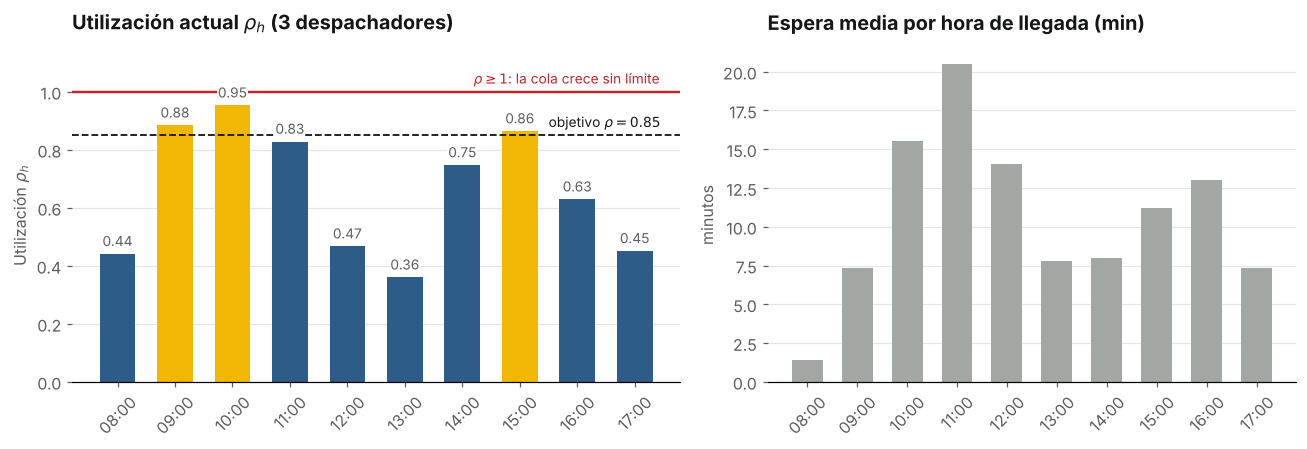

**Lectura.** Ninguna hora llega a $\rho = 1$ (el máximo es **0.95** a las 10:00); superan el objetivo de 0.85 las 09:00, 10:00, 15:00. La espera máxima (20.5 min) aparece a las 11:00, una hora *después* del pico de llegadas: la cola formada a las 9–10 h se arrastra. Con $\rho_h$ hora por hora esto no se ve.

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
rho = diag["Rho (Utilización)"]
colores = [COLOR["alerta"] if r >= 1 else COLOR["aviso"] if r > 0.85 else COLOR["plan"] for r in rho]
barras = ax[0].bar(diag["Hora"], rho, color=colores, width=0.62)
ax[0].bar_label(barras, fmt="%.2f", padding=3, color=COLOR["tinta2"], fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
ax[0].axhline(0.85, color=COLOR["tinta"], ls="--", lw=1.2)
ax[0].axhline(1.00, color=COLOR["alerta"], lw=1.6)
ax[0].text(9.45, 0.865, r"objetivo $\rho = 0.85$", ha="right", va="bottom", fontsize=9)
ax[0].text(9.45, 1.015, r"$\rho \geq 1$: la cola crece sin límite", ha="right", va="bottom", fontsize=9, color=COLOR["alerta"])
ax[0].set_ylim(0, max(1.15, rho.max() + 0.12)); ax[0].tick_params(axis="x", labelrotation=45)
ax[0].set_title(r"Utilización actual $\rho_h$ (3 despachadores)"); ax[0].set_ylabel(r"Utilización $\rho_h$")
ax[1].bar(diag["Hora"], diag["Espera Media (Min)"], color=COLOR["actual"], width=0.62)
ax[1].set_title("Espera media por hora de llegada (min)"); ax[1].set_ylabel("minutos"); ax[1].tick_params(axis="x", labelrotation=45)
plt.tight_layout(); plt.show()

pico = diag.loc[diag["Espera Media (Min)"].idxmax()]
sobre = diag.loc[diag["Rho (Utilización)"] > 0.85, "Hora"].tolist()
display(Markdown(
    f"**Lectura.** Ninguna hora llega a $\\rho = 1$ (el máximo es **{rho.max():.2f}** a las {diag.loc[rho.idxmax(), 'Hora']}); "
    f"superan el objetivo de 0.85 las {', '.join(sobre) if sobre else 'ninguna hora'}. "
    f"La espera máxima ({pico['Espera Media (Min)']:.1f} min) aparece a las {pico['Hora']}, una hora *después* del pico de llegadas: "
    f"la cola formada a las 9–10 h se arrastra. Con $\\rho_h$ hora por hora esto no se ve."))

## 2. ¿Qué explica la venta perdida?

Cada pedido del archivo trae la causa de su pérdida. Se clasifican en tres grupos según lo que pueda corregir el plan de personal:

* **Quiebre de stock:** no había mercadería. Más despachadores no lo arreglan.
* **Calendario:** el pedido llega después de las 15 h o en sábado, y ya no hay camión ese día (sale al día hábil siguiente). Tampoco depende del personal.
* **Despacho:** el pedido no estuvo listo a tiempo, perdió su camión y la entrega se atrasó. **Es lo único que el plan de personal puede corregir.**

Causa,Pedidos,Venta perdida (S/),Grupo,% del total
Cancelación con quiebre de stock,353,"917,940.25",quiebre,50.4 %
Cliente perdido tras entrega tardía por quiebre de stock,72,"388,621.06",quiebre,21.3 %
Cancelación sin quiebre (el pedido llega después de las 15 h),113,"282,839.36",calendario,15.5 %
Cliente perdido por calendario (sábado o pedido de fin de día),41,"221,893.98",calendario,12.2 %
Cliente perdido tras perder la ruta (despacho),2,"9,426.28",despacho,0.5 %


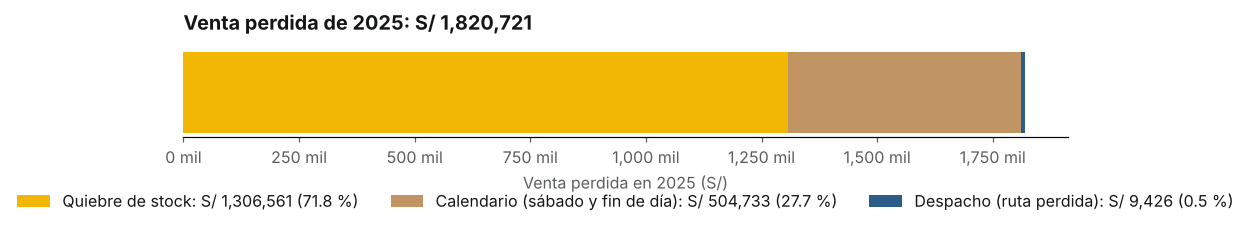

**Lectura.** De S/ 1,820,721 perdidos en 2025, solo **S/ 9,426 (0.5 %)** se debe a pedidos que perdieron su camión. El 72 % viene de quiebres de stock y el 28 % del calendario de camiones. Esto condiciona todo lo que sigue: el personal de despacho puede mejorar la espera y las rutas, pero **no recupera la mayor parte de lo que se pierde**.

In [5]:
causas = pd.DataFrame([(nombre, n, monto, grupo) for nombre, (n, monto, grupo) in PAR["causas"].items()],
                      columns=["Causa", "Pedidos", "Venta perdida (S/)", "Grupo"])
total_perdida = causas["Venta perdida (S/)"].sum()
causas["% del total"] = 100 * causas["Venta perdida (S/)"] / total_perdida
display(causas.sort_values("Venta perdida (S/)", ascending=False).style.hide(axis="index")
        .format({"Venta perdida (S/)": "{:,.2f}", "% del total": "{:.1f} %"}))

por_grupo = causas.groupby("Grupo")["Venta perdida (S/)"].sum().reindex(["quiebre", "calendario", "despacho"])
etiquetas_g = {"quiebre": "Quiebre de stock", "calendario": "Calendario (sábado y fin de día)", "despacho": "Despacho (ruta perdida)"}
fig, ax = plt.subplots(figsize=(11, 2.8))
izq = 0
for g, v in por_grupo.items():
    ax.barh([0], [v], left=izq, color=COLOR_CAUSA[g], height=0.5, label=f"{etiquetas_g[g]}: {soles(v)} ({100 * v / total_perdida:.1f} %)")
    izq += v
ax.set_yticks([]); ax.xaxis.set_major_formatter(k_soles); ax.grid(False); ax.set_xlabel("Venta perdida en 2025 (S/)")
ax.set_title(f"Venta perdida de 2025: {soles(total_perdida)}"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=3)
plt.tight_layout(); plt.show()

VENTA_DESPACHO_2025 = float(por_grupo["despacho"])
display(Markdown(
    f"**Lectura.** De {soles(total_perdida)} perdidos en 2025, solo **{soles(VENTA_DESPACHO_2025)} ({100 * VENTA_DESPACHO_2025 / total_perdida:.1f} %)** "
    f"se debe a pedidos que perdieron su camión. El {100 * por_grupo['quiebre'] / total_perdida:.0f} % viene de quiebres de stock y el "
    f"{100 * por_grupo['calendario'] / total_perdida:.0f} % del calendario de camiones. Esto condiciona todo lo que sigue: "
    f"el personal de despacho puede mejorar la espera y las rutas, pero **no recupera la mayor parte de lo que se pierde**."))

## 3. Formulación matemática del modelo de programación entera (shift scheduling)

Para estabilizar el sistema de colas se determina el personal mínimo por hora ($D_h$) que mantiene la utilización en un nivel que representa el **estándar de nivel de servicio** ($\rho_h \le 0.85$):

$$D_h = \max\left(1, \left\lceil \frac{\lambda_h}{0.85 \cdot \mu} \right\rceil\right)$$

### 3.1 Variables de decisión (turnos laborales realistas)
* $X_j \in \mathbb{Z}^+$: personal a tiempo completo (**Full-Time**) en el turno $j \in \{1, 2, 3\}$.
  * **$X_1$ (FT-1)**: ingreso 08:00, almuerzo 12:00–13:00, salida 17:00.
  * **$X_2$ (FT-2)**: ingreso 08:00, almuerzo 13:00–14:00, salida 17:00.
  * **$X_3$ (FT-3)**: ingreso 09:00, almuerzo 14:00–15:00, salida 18:00.
* $Y_k \in \mathbb{Z}^+$: personal a tiempo parcial (**Part-Time**) de 4 horas continuas en el turno $k \in \{1, 2, 3\}$.
  * **$Y_1$ (PT-1)**: 09:00–13:00. **$Y_2$ (PT-2)**: 10:00–14:00. **$Y_3$ (PT-3)**: 14:00–18:00.

### 3.2 Costos de planilla mensual (legislación laboral peruana)
* **Tiempo completo ($C_{FT}$):** sueldo mínimo S/ 1,025 + EsSalud (9 %) S/ 92.25 + beneficios proporcionales (CTS, gratificación, seguro de vida) ≈ **S/ 1,373.50 al mes**.
* **Tiempo parcial ($C_{PT}$):** sueldo proporcional S/ 512.50 + EsSalud (9 %) S/ 46.13 + provisiones ≈ **S/ 686.76 al mes**.

### 3.3 Función objetivo
$$\text{Minimizar } Z = 1373.50 \sum_{j=1}^{3} X_j + 686.76 \sum_{k=1}^{3} Y_k$$

### 3.4 Restricciones
* **Nivel de servicio:** en cada hora $h$, los despachadores activos deben ser al menos $D_h$: $\;Capacidad_h \ge D_h \quad \forall h \in \{8, \dots, 17\}$.
* **Legal (D.S. 003-97-TR):** el part-time no puede superar el 40 % del personal: $\;-0.40 \sum X_j + 0.60 \sum Y_k \le 0$.

## 4. Resolución con Google OR-Tools (solver SCIP)

La cobertura de cada turno se define **una sola vez** (`TURNOS`) y de ella salen las 10 restricciones del modelo y, más adelante, el personal que usa la simulación.

In [6]:
C_FT, C_PT = 1373.50, 686.76                 # costo mensual por trabajador (S/)
TURNOS = {                                   # horas (inicio de cada intervalo) en que trabaja cada turno
    "FT-1": [8, 9, 10, 11, 13, 14, 15, 16],  # 08-17, almuerzo 12-13
    "FT-2": [8, 9, 10, 11, 12, 14, 15, 16],  # 08-17, almuerzo 13-14
    "FT-3": [9, 10, 11, 12, 13, 15, 16, 17], # 09-18, almuerzo 14-15
    "PT-1": [9, 10, 11, 12],                 # 09-13
    "PT-2": [10, 11, 12, 13],                # 10-14
    "PT-3": [14, 15, 16, 17],                # 14-18
}
es_parcial = lambda t: t.startswith("PT")


def requeridos(rho):
    # D_h: despachadores mínimos por hora para que la utilización no pase de rho (mínimo 1 por seguridad)
    return {h: max(1, int(np.ceil(LAMBDA[h] / (rho * MU_H)))) for h in HORAS}


def optimizar(rho):
    # MILP de turnos: mínimo costo de planilla que cubre D_h en cada hora y respeta el 40 % de part-time
    req = requeridos(rho)
    s = pywraplp.Solver.CreateSolver("SCIP")
    x = {t: s.IntVar(0, 10, t) for t in TURNOS}
    for h in HORAS:
        s.Add(sum(x[t] for t in x if h in TURNOS[t]) >= req[h], f"NivelServicio_{h:02d}")
    ft = sum(v for t, v in x.items() if not es_parcial(t))
    pt = sum(v for t, v in x.items() if es_parcial(t))
    s.Add(-0.40 * ft + 0.60 * pt <= 0, "Proporcion_PT_Max_40")
    s.Minimize(C_FT * ft + C_PT * pt)
    assert s.Solve() == pywraplp.Solver.OPTIMAL, "El MILP no tiene solución"
    return {t: round(v.solution_value()) for t, v in x.items() if v.solution_value() > 0.5}


def costo_mensual(plan):
    return sum(n * (C_PT if es_parcial(t) else C_FT) for t, n in plan.items())


RHO_OBJETIVO = 0.85
req_h = requeridos(RHO_OBJETIVO)
plan_optimo = optimizar(RHO_OBJETIVO)
costo_optimo = costo_mensual(plan_optimo)

print("=== REQUERIMIENTO MÍNIMO DE DESPACHADORES (D_h) ===")
print("  ".join(f"{h:02d}h: {n}" for h, n in req_h.items()))
print(f"\n=== SOLUCIÓN ÓPTIMA (rho <= {RHO_OBJETIVO}) ===")
print(f"Costo de planilla del almacén: {soles(costo_optimo)} al mes  ({soles(12 * costo_optimo)} al año)  "
      f"| hoy: {soles(C_ACTUAL * C_FT)} al mes")
for t in TURNOS:
    print(f"  {t}: {plan_optimo.get(t, 0)} despachador(es)")

=== REQUERIMIENTO MÍNIMO DE DESPACHADORES (D_h) ===
08h: 2  09h: 4  10h: 4  11h: 3  12h: 2  13h: 2  14h: 3  15h: 4  16h: 3  17h: 2

=== SOLUCIÓN ÓPTIMA (rho <= 0.85) ===
Costo de planilla del almacén: S/ 5,494 al mes  (S/ 65,928 al año)  | hoy: S/ 4,120 al mes
  FT-1: 2 despachador(es)
  FT-2: 0 despachador(es)
  FT-3: 1 despachador(es)
  PT-1: 1 despachador(es)
  PT-2: 0 despachador(es)
  PT-3: 1 despachador(es)


### Cobertura final frente al requerimiento teórico

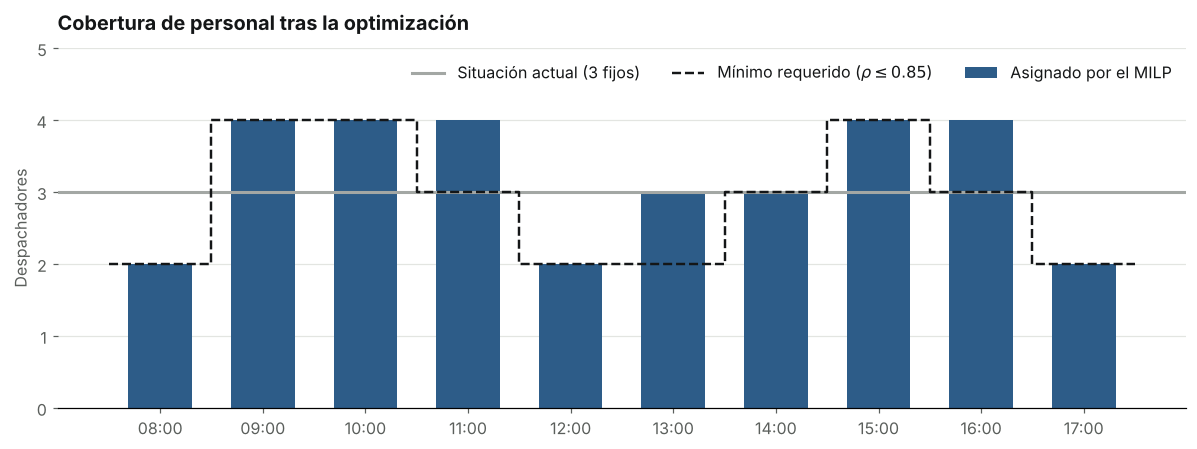

In [7]:
def personal_por_hora(plan, turnos=TURNOS):
    # Despachadores en turno en cada hora para un plan {turno: cantidad}
    return {h: sum(n for t, n in plan.items() if h in turnos[t]) for h in HORAS}


cobertura = personal_por_hora(plan_optimo)
comparativo = pd.DataFrame({"Hora": [f"{h:02d}:00" for h in HORAS], "Mín. requerido": [req_h[h] for h in HORAS],
                            "Asignado óptimo": [cobertura[h] for h in HORAS]})

fig, ax = plt.subplots()
x = np.arange(len(HORAS))
ax.bar(x, comparativo["Asignado óptimo"], 0.62, color=COLOR["plan"], label="Asignado por el MILP")
ax.axhline(C_ACTUAL, color=COLOR["actual"], lw=2, label="Situación actual (3 fijos)")
ax.step(np.r_[x - 0.5, x[-1] + 0.5], np.r_[comparativo["Mín. requerido"], comparativo["Mín. requerido"].iloc[-1]],
        where="post", color=COLOR["tinta"], ls="--", lw=1.6, label=r"Mínimo requerido ($\rho \leq 0.85$)")
ax.set_xticks(x, comparativo["Hora"]); ax.set_yticks(range(0, int(comparativo["Asignado óptimo"].max()) + 2))
ax.set_title("Cobertura de personal tras la optimización"); ax.set_ylabel("Despachadores"); ax.legend(loc="upper right", ncol=3)
plt.tight_layout(); plt.show()

## 5. Análisis financiero analítico (supuesto original)

El análisis original supone que, con la planilla optimizada, **se retiene el 95 % de las ventas que hoy se pierden**. Eso solo es cierto si *toda* la venta perdida se debe al despacho. El capítulo 2 muestra que no es así; se calculan las dos lecturas.

In [8]:
RECUPERACION_SUPUESTA = 0.95
tasa_cancelados = PAR["cancelado_pct"]
ventas_perdidas_anuales = PAR["venta_perdida"]
cancelados_2025 = PAR["cancelados"]
TICKET = PAR["monto_media"]                                         # S/ promedio de un pedido

planilla_actual_anual = C_ACTUAL * C_FT * 12
planilla_optima_anual = costo_optimo * 12
inversion_adicional = planilla_optima_anual - planilla_actual_anual


def roi(recuperable):
    recuperado = recuperable * RECUPERACION_SUPUESTA
    beneficio = recuperado - inversion_adicional
    return recuperado, beneficio, 100 * beneficio / inversion_adicional


print(f"Venta perdida anual (todas las causas):        {soles(ventas_perdidas_anuales)}")
print(f"Venta perdida atribuible al despacho:          {soles(VENTA_DESPACHO_2025)}")
print(f"Inversión adicional de planilla:               {soles(inversion_adicional)} al año")
print("-" * 78)
for nombre, base_ in [("Supuesto original (toda la venta perdida es recuperable)", ventas_perdidas_anuales),
                      ("Solo la parte atribuible al despacho", VENTA_DESPACHO_2025)]:
    rec, ben, r = roi(base_)
    print(f"{nombre}\n   recuperado {soles(rec)} | beneficio neto {soles(ben)} | ROI {r:,.0f} %")

Venta perdida anual (todas las causas):        S/ 1,820,721
Venta perdida atribuible al despacho:          S/ 9,426
Inversión adicional de planilla:               S/ 16,482 al año
------------------------------------------------------------------------------
Supuesto original (toda la venta perdida es recuperable)
   recuperado S/ 1,729,685 | beneficio neto S/ 1,713,203 | ROI 10,394 %
Solo la parte atribuible al despacho
   recuperado S/ 8,955 | beneficio neto −S/ 7,527 | ROI -46 %


# PARTE II — SIMULACIÓN DE EVENTOS DISCRETOS

**Objetivo:** validar con simulación el plan de personal de la Parte I y medir qué cambia de verdad con él.

El modelo $M/M/c$ analiza cada hora **por separado y en estado estable**. En la realidad la cola formada a las 9–10 h **se arrastra** a las horas siguientes, los almuerzos reducen la capacidad, los camiones salen a horas fijas y la demanda varía día a día. La simulación (SimPy) reproduce pedido por pedido cada jornada durante 299 días operativos para responder:

1. ¿El plan óptimo reduce la espera y la pérdida de ruta? ¿Cuánto de la venta perdida recupera de verdad?
2. ¿Hasta qué crecimiento de la demanda aguanta?
3. ¿Qué pasa si falta personal (ausentismo)?
4. ¿Es $\rho = 0.85$ el mejor objetivo, considerando planilla + horas extra + ventas perdidas?
5. ¿Cambia la decisión según el margen bruto? ¿Y frente a atacar los quiebres de stock?

## 6. Modelo de simulación

El modelo reproduce las reglas que se observan en los datos de 2025.

| Elemento | Regla (estimada de los datos) |
|---|---|
| Llegadas | Poisson por hora con tasa $\lambda_h$ (capítulo 1), multiplicada por un factor por día de la semana (lunes–sábado) |
| Quiebre de stock | Cada pedido tiene probabilidad $q$ de encontrar un quiebre; la reposición tarda 1–4 días |
| Cancelación | Depende de los días de reposición y de si el pedido llega después de las 15 h. Un pedido cancelado no entra a la cola |
| Preparación | Gamma con media 44.5 min y coeficiente de variación 0.40 (no exponencial). Orden de llegada, un pedido por despachador |
| Turnos | Los del MILP, con almuerzo. Al salir, el despachador **termina el pedido en curso**. La situación actual son 3 despachadores de 8 a 18 h |
| Camión | Salen a las 10:00, 13:00 y 16:00. Cada pedido se asigna a la primera salida que alcanza con su tiempo de preparación; **pierde la ruta si no está listo a la salida** y va en el camión siguiente (o al día hábil siguiente; el sábado, al lunes) |
| Entrega tardía | Más de 24 h entre la llegada y la entrega (tránsito de 0.3 a 2 h). Los quiebres no cancelados siempre llegan tarde |
| Cliente perdido | Tras una entrega tardía se pierde el cliente con probabilidad $\approx$ 16 %, y con él el valor de 2 pedidos futuros |
| Cierre | Lo pendiente a las 18:00 se despacha con horas extra (personal de las 17 h, mínimo 1): S/ 5.34/h (sueldo base / 240 h + 25 %) |
| Venta perdida | Cancelación: el monto del pedido. Cliente perdido: el doble. Se valora al margen bruto (`MARGEN`; 100 % = precio de venta) |

No quedan parámetros por calibrar: todo sale de los datos. Para modelar la capacidad variable se usa un `PriorityResource`: cuando un despachador sale de turno, un "bloqueo" de prioridad alta ocupa su puesto apenas termina su pedido actual.

In [9]:
# --- Parámetros de la simulación (todos estimados de los datos de 2025) ---
SALIDAS = [120, 300, 480]                     # camiones de las 10:00, 13:00 y 16:00, en minutos desde las 08:00
LLEGADA_TARDE = 420                           # 15:00: desde aquí ya no sale camión ese día
CIERRE = 600                                  # 18:00
COSTO_HORA_EXTRA = 1025 / 240 * 1.25          # hora simple del sueldo base + 25 % (D.S. 007-2002-TR)
MARGEN = 1.0                                  # margen bruto de un pedido; 1.0 = venta perdida a precio de venta
R = 10                                        # réplicas (años simulados) por escenario
T_STUDENT = 2.262                             # t(0.975, R-1 = 9) para intervalos de confianza al 95 %

K_SERVICIO = (PAR["servicio_media"] / PAR["servicio_sd"]) ** 2          # forma de la Gamma de la preparación
K_MONTO = (PAR["monto_media"] / PAR["monto_sd"]) ** 2
CANCELA = {"quiebre": {False: PAR["cancel_quiebre_temprano"], True: PAR["cancel_quiebre_tarde"]},
           "sin_quiebre": {False: 0.0, True: PAR["cancel_sin_quiebre_tarde"]}}
FACTOR_DIA = [float(v) for v in PAR["factor_dia"]]                # lunes a sábado

# La situación actual es un "turno" más: 3 despachadores de 08 a 18 sin descontar almuerzo
TURNOS_SIM = {**TURNOS, "ACTUAL": list(HORAS)}
PLAN_ACTUAL = {"ACTUAL": C_ACTUAL}
PLAN_OPTIMO = dict(plan_optimo)

Pedido = namedtuple("Pedido", "t quiebre cancela prep monto u_cliente transito id", defaults=[0])
print(f"Pedidos/día esperados: {sum(LAMBDA.values()):.1f} | ticket promedio S/ {TICKET:,.2f} | "
      f"preparación Gamma(k = {K_SERVICIO:.2f}, media {MU_MIN} min) | quiebres {100 * PAR['p_quiebre']:.1f} %")
print("Despachadores por hora, plan óptimo:", personal_por_hora(PLAN_OPTIMO, TURNOS_SIM))

Pedidos/día esperados: 26.8 | ticket promedio S/ 2,475.00 | preparación Gamma(k = 6.19, media 44.5 min) | quiebres 10.3 %
Despachadores por hora, plan óptimo: {8: 2, 9: 4, 10: 4, 11: 4, 12: 2, 13: 3, 14: 3, 15: 4, 16: 4, 17: 2}


In [10]:
def generar_dia(rng, dia, crecimiento=0.0, q_quiebre=1.0):
    # Los pedidos de una jornada. Es independiente del personal: con la misma semilla, todos los planes ven los mismos pedidos.
    # Cada pedido consume siempre las mismas variables aleatorias, así que cambiar un parámetro no desordena el resto.
    factor = FACTOR_DIA[dia % 6] * (1 + crecimiento)
    pedidos = []
    for i, h in enumerate(HORAS):
        for t in 60 * i + rng.uniform(0, 60, rng.poisson(LAMBDA[h] * factor)):
            u_q, dias_rep, u_c, prep, monto, u_cl, transito = (rng.random(), rng.integers(1, 5), rng.random(),
                                                                rng.gamma(K_SERVICIO, MU_MIN / K_SERVICIO),
                                                                rng.gamma(K_MONTO, PAR["monto_media"] / K_MONTO), rng.random(),
                                                                rng.uniform(*PAR["transito_h"]))
            quiebre = u_q < PAR["p_quiebre"] * q_quiebre
            p_cancela = CANCELA["quiebre"][t >= LLEGADA_TARDE][dias_rep - 1] if quiebre else CANCELA["sin_quiebre"][t >= LLEGADA_TARDE]
            pedidos.append(Pedido(t, quiebre, u_c < p_cancela, prep, monto, u_cl, transito))
    return sorted(pedidos)


def evaluar_ruta(t, prep, espera, transito_h, dia):
    # Devuelve (perdió la ruta, entrega tardía). Cada pedido se asigna a la primera salida que alcanza con su preparación.
    manana = SALIDAS[0] + 1440 * (2 if dia % 6 == 5 else 1)               # el sábado, el siguiente camión es el del lunes
    d0 = next((s for s in SALIDAS if s >= t + prep), None)
    if d0 is None:
        salida, perdio = manana, False
    else:
        perdio = t + espera + prep > d0
        salida = next((s for s in SALIDAS if s > d0), manana) if perdio else d0
    return perdio, salida + 60 * transito_h - t > 1440


def procesar_dia(pedidos, personal_h, dia):
    # Una jornada en SimPy. Devuelve una fila por pedido y los minutos-persona trabajados después de las 18:00.
    # Fila: (hora, espera, perdió ruta, tardía, cancelado, cliente perdido, quiebre, monto, venta perdida, causa, id)
    env = simpy.Environment()
    cap = max(1, max(personal_h.values()))
    almacen = simpy.PriorityResource(env, capacity=cap)
    registros, extra_min = [], 0.0

    def control_turnos():
        bloqueos = []
        for n in [personal_h[h] for h in HORAS] + [max(1, personal_h[17])]:   # último = horas extra
            while len(bloqueos) < cap - n:
                bloqueos.append(almacen.request(priority=-1))
            while len(bloqueos) > cap - n:
                b = bloqueos.pop()
                almacen.release(b) if b.triggered else b.cancel()
            yield env.timeout(60)

    def atender(p):
        nonlocal extra_min
        hora = HORAS[min(int(p.t // 60), 9)]
        if p.cancela:
            causa = "quiebre" if p.quiebre else "calendario"
            registros.append((hora, 0.0, False, False, True, False, p.quiebre, p.monto, p.monto, causa, p.id))
            return
        req = almacen.request(priority=0)
        yield req
        espera = env.now - p.t
        if p.quiebre:                                                          # se entrega tras la reposición
            perdio, tardia, causa = False, True, "quiebre"
        else:
            perdio, tardia = evaluar_ruta(p.t, p.prep, espera, p.transito, dia)
            causa = "despacho" if perdio else "calendario"
        perdido = tardia and p.u_cliente < PAR["p_cliente_perdido"]
        registros.append((hora, espera, perdio, tardia, False, perdido, p.quiebre, p.monto, 2 * p.monto if perdido else 0.0, causa, p.id))
        extra_min += max(0.0, env.now + p.prep - max(env.now, CIERRE))
        yield env.timeout(p.prep)
        almacen.release(req)

    def llegadas():
        for p in pedidos:
            yield env.timeout(p.t - env.now)
            env.process(atender(p))

    env.process(control_turnos())
    env.process(llegadas())
    env.run()
    return registros, extra_min


COLUMNAS = ["hora", "espera", "perdio_ruta", "tardia", "cancelado", "cliente_perdido", "quiebre", "monto", "venta_perdida", "causa", "id"]


def simular_anio(plan, seed, crecimiento=0.0, ausentismo=0.0, q_quiebre=1.0):
    # Un año = 299 jornadas independientes. Ausentismo: cada trabajador falta con esa probabilidad diaria.
    rng_pedidos, rng_aus = np.random.default_rng([seed, 1]), np.random.default_rng([seed, 2])
    filas, extra_min = [], 0.0
    for dia in range(DIAS):
        pedidos = generar_dia(rng_pedidos, dia, crecimiento, q_quiebre)
        presentes = {t: rng_aus.binomial(n, 1 - ausentismo) for t, n in plan.items()}
        registros, extra = procesar_dia(pedidos, personal_por_hora(presentes, TURNOS_SIM), dia)
        filas += registros
        extra_min += extra
    df_anio = pd.DataFrame(filas, columns=COLUMNAS)
    df_anio.attrs["horas_extra"] = extra_min / 60
    return df_anio


def indicadores(df_anio, plan):
    venta = df_anio["venta_perdida"]
    por_causa = df_anio.groupby("causa")["venta_perdida"].sum()
    planilla = 12 * costo_mensual(plan)
    horas_extra = df_anio.attrs["horas_extra"]
    return {"Pedidos": len(df_anio),
            "Espera media (min)": df_anio["espera"].mean(),
            "Pérdida de ruta (%)": 100 * df_anio["perdio_ruta"].mean(),
            "Entregas tardías (%)": 100 * df_anio["tardia"].mean(),
            "Cancelados (%)": 100 * df_anio["cancelado"].mean(),
            "Clientes perdidos (%)": 100 * df_anio["cliente_perdido"].mean(),
            "Venta perdida (S/)": venta.sum(),
            "  por quiebre (S/)": por_causa.get("quiebre", 0.0),
            "  por calendario (S/)": por_causa.get("calendario", 0.0),
            "  por despacho (S/)": por_causa.get("despacho", 0.0),
            "Margen perdido (S/)": venta.sum() * MARGEN,
            "Horas extra (h/año)": horas_extra,
            "Costo horas extra (S/)": horas_extra * COSTO_HORA_EXTRA,
            "Planilla anual (S/)": planilla,
            "Costo total (S/)": planilla + horas_extra * COSTO_HORA_EXTRA + venta.sum() * MARGEN}


def replicar(plan, **kw):
    # Mismas semillas en todos los escenarios = números aleatorios comunes (reduce la varianza al comparar)
    return pd.DataFrame([indicadores(simular_anio(plan, seed=s, **kw), plan) for s in range(R)])


def media_ic(reps):
    return pd.DataFrame({"Media": reps.mean(), "± IC 95%": T_STUDENT * reps.std() / np.sqrt(R)})


etiquetas = [f"{h:02d}h" for h in HORAS]
x = np.arange(len(HORAS))


def barras_por_hora(ax, series, titulo, ylabel, anotar=None):
    # Barras agrupadas por hora de llegada. series = {nombre: (valores, color)}
    ancho = 0.8 / len(series)
    for i, (nombre, (valores, color)) in enumerate(series.items()):
        ax.bar(x + (i - (len(series) - 1) / 2) * ancho, valores, ancho * 0.92, label=nombre, color=color)
    ax.set_xticks(x, etiquetas); ax.set_title(titulo); ax.set_ylabel(ylabel); ax.legend()
    if anotar:
        ax.annotate(anotar[0], xy=anotar[1], xytext=anotar[2], fontsize=9, color=COLOR["alerta"],
                    arrowprops=dict(arrowstyle="-", color=COLOR["alerta"], lw=1), ha="center")

## 7. Validación del modelo

**Prueba determinista (necesita el CSV).** Se toman los 8 012 pedidos reales —hora de llegada, tiempo de preparación, cancelación, tránsito— y se pasan por el mismo simulador con los despachadores de cada día. Si las reglas son las correctas, las esperas y las rutas perdidas deben salir **idénticas** a las del archivo.

**Prueba estadística.** Se simulan años completos con pedidos generados al azar y se comparan los totales y el perfil por hora con 2025.

In [11]:
if df is None:
    print("Prueba determinista omitida: no se encontró denlu_colab_2025.csv (el resto del cuaderno no la necesita).")
else:
    dias_sem = {"Lunes": 0, "Martes": 1, "Miércoles": 2, "Jueves": 3, "Viernes": 4, "Sábado": 5}
    t_ll = pd.to_datetime(df["fecha"] + " " + df["hora_llegada"])
    df = df.assign(min8=t_ll.dt.hour * 60 + t_ll.dt.minute + t_ll.dt.second / 60 - 480,
                   transito=((pd.to_datetime(df["entrega_fecha_hora"], errors="coerce") - pd.to_datetime(df["salida_ruta"], errors="coerce"))
                             .dt.total_seconds() / 3600).fillna(1.0))
    filas = []
    for _, g in df.groupby("fecha"):
        pedidos = [Pedido(r.min8, bool(r.quiebre_stock), bool(r.cancelado), r.tiempo_preparacion_min, r.monto_pedido_S, 1.0, r.transito, r.id_pedido)
                   for r in g.sort_values("min8").itertuples()]
        c = int(g["n_despachadores"].max())                                   # 3 despachadores, o 4 en los días de refuerzo
        regs, _ = procesar_dia(pedidos, {h: c for h in HORAS}, dias_sem[g["dia_semana"].iloc[0]])
        filas.append(pd.DataFrame(regs, columns=COLUMNAS))
    rep = pd.concat(filas).merge(df[["id_pedido", "tiempo_espera_min", "perdio_ruta", "entrega_tardia", "quiebre_stock"]]
                                 .rename(columns={"id_pedido": "id", "perdio_ruta": "perdio_csv", "entrega_tardia": "tardia_csv"}), on="id")
    sin_q = rep[rep["quiebre_stock"] == 0]
    exacta = (rep["espera"] - rep["tiempo_espera_min"]).abs() < 0.05          # el archivo redondea a centésimas de minuto
    print(f"Pedidos repetidos por el simulador: {len(rep):,}")
    print(f"Espera idéntica (±3 segundos):      {100 * exacta.mean():.2f} % de los pedidos (espera media {rep['espera'].mean():.2f} vs {rep['tiempo_espera_min'].mean():.2f} min)")
    print(f"Pérdida de ruta idéntica:           {100 * (sin_q['perdio_ruta'].astype(int) == sin_q['perdio_csv']).mean():.2f} % de los pedidos sin quiebre")
    print(f"Entrega tardía idéntica:            {100 * (rep['tardia'].astype(int) == rep['tardia_csv']).mean():.2f} % de los pedidos")

Pedidos repetidos por el simulador: 8,012
Espera idéntica (±3 segundos):      100.00 % de los pedidos (espera media 11.38 vs 11.38 min)
Pérdida de ruta idéntica:           100.00 % de los pedidos sin quiebre
Entrega tardía idéntica:            99.44 % de los pedidos


,2025,Simulado,± IC 95 %
Indicador,,,
Pedidos al año,"8,012.00","8,028.80",80.20
Espera media (min),11.38,11.70,0.53
Pérdida de ruta (%),5.27,5.63,0.24
Entregas tardías (%),8.92,8.79,0.18
Pedidos cancelados (%),5.82,5.89,0.31
Clientes perdidos (%),1.44,1.40,0.06
Venta perdida (S/),"1,820,720.93","1,741,048.07","76,841.67"


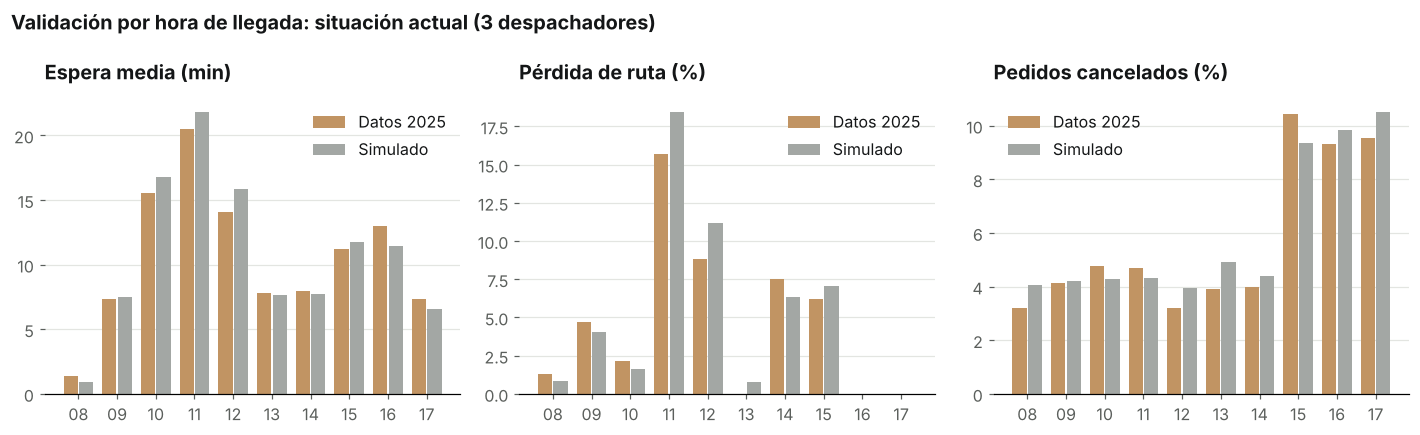

**Lectura.** El modelo reproduce el almacén real. Los totales de 2025 caen dentro o muy cerca del intervalo simulado (7 de 7 indicadores a menos de 1.5 intervalos), y el perfil por hora tiene la misma forma: la espera máxima cae a las 11 h, la pérdida de ruta es nula a las 13, 16 y 17 h (no hay camión que perder) y la cancelación sube después de las 15 h. Error cuadrático medio por hora: 1.0 min de espera y 1.3 puntos de pérdida de ruta.

El modelo usa 3 despachadores fijos. En 24 de 299 días de 2025 hubo un cuarto despachador (días de más pedidos); esos días no se modelan por separado.

In [12]:
# Prueba estadística: situación actual simulada (años completos) vs. 2025
anios_df = [simular_anio(PLAN_ACTUAL, seed=s) for s in range(R)]
sim_actual = pd.concat(anios_df)
anios = [indicadores(d, PLAN_ACTUAL) for d in anios_df]
ic = lambda k: T_STUDENT * pd.DataFrame(anios)[k].std() / np.sqrt(R)
mid = lambda k: pd.DataFrame(anios)[k].mean()
comp = pd.DataFrame([
    ("Pedidos al año", PAR["pedidos"], mid("Pedidos"), ic("Pedidos")),
    ("Espera media (min)", PAR["espera_media"], mid("Espera media (min)"), ic("Espera media (min)")),
    ("Pérdida de ruta (%)", PAR["perdio_ruta_pct"], mid("Pérdida de ruta (%)"), ic("Pérdida de ruta (%)")),
    ("Entregas tardías (%)", PAR["tardia_pct"], mid("Entregas tardías (%)"), ic("Entregas tardías (%)")),
    ("Pedidos cancelados (%)", PAR["cancelado_pct"], mid("Cancelados (%)"), ic("Cancelados (%)")),
    ("Clientes perdidos (%)", PAR["cliente_perdido_pct"], mid("Clientes perdidos (%)"), ic("Clientes perdidos (%)")),
    ("Venta perdida (S/)", PAR["venta_perdida"], mid("Venta perdida (S/)"), ic("Venta perdida (S/)")),
], columns=["Indicador", "2025", "Simulado", "± IC 95 %"]).set_index("Indicador")
display(comp.style.format("{:,.2f}"))

por_hora = sim_actual.groupby("hora").agg(espera=("espera", "mean"), perdio=("perdio_ruta", "mean"), cancel=("cancelado", "mean"))
fig, ax = plt.subplots(1, 3, figsize=(13, 4.0))
for a, hist, sim, titulo, f in [(ax[0], PAR["espera_h"], por_hora["espera"], "Espera media (min)", 1),
                                (ax[1], PAR["perdio_ruta_h"], por_hora["perdio"], "Pérdida de ruta (%)", 100),
                                (ax[2], PAR["cancelado_h"], por_hora["cancel"], "Pedidos cancelados (%)", 100)]:
    barras_por_hora(a, {"Datos 2025": (hist, COLOR["hist"]), "Simulado": (f * sim, COLOR["actual"])}, titulo, "")
    a.set_xticks(x, [e[:2] for e in etiquetas])
fig.suptitle("Validación por hora de llegada: situación actual (3 despachadores)", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

rmse = lambda a, b: float(np.sqrt(np.mean((np.array(a) - np.array(b)) ** 2)))
r_esp = rmse(PAR["espera_h"], por_hora["espera"]); r_per = rmse(PAR["perdio_ruta_h"], 100 * por_hora["perdio"])
dentro = int((((comp["2025"] - comp["Simulado"]).abs() <= comp["± IC 95 %"] * 1.5)).sum())
display(Markdown(
    f"**Lectura.** El modelo reproduce el almacén real. Los totales de 2025 caen dentro o muy cerca del intervalo simulado "
    f"({dentro} de {len(comp)} indicadores a menos de 1.5 intervalos), y el perfil por hora tiene la misma forma: la espera máxima "
    f"cae a las {HORAS[int(np.argmax(por_hora['espera'].to_numpy()))]} h, la pérdida de ruta es nula a las 13, 16 y 17 h (no hay camión que perder) y la cancelación sube después de las 15 h. "
    f"Error cuadrático medio por hora: {r_esp:.1f} min de espera y {r_per:.1f} puntos de pérdida de ruta.\n\n"
    f"El modelo usa 3 despachadores fijos. En {PAR['dias_refuerzo']} de {PAR['dias']} días de 2025 hubo un cuarto despachador (días de más pedidos); "
    f"esos días no se modelan por separado."))

## 8. Escenario 1 — Situación actual vs. plan óptimo (MILP, $\rho = 0.85$)

In [13]:
reps = {"Actual": replicar(PLAN_ACTUAL), "Óptimo": replicar(PLAN_OPTIMO)}
tabla = pd.concat({k: media_ic(v) for k, v in reps.items()}, axis=1)
display(tabla.style.format("{:,.2f}"))

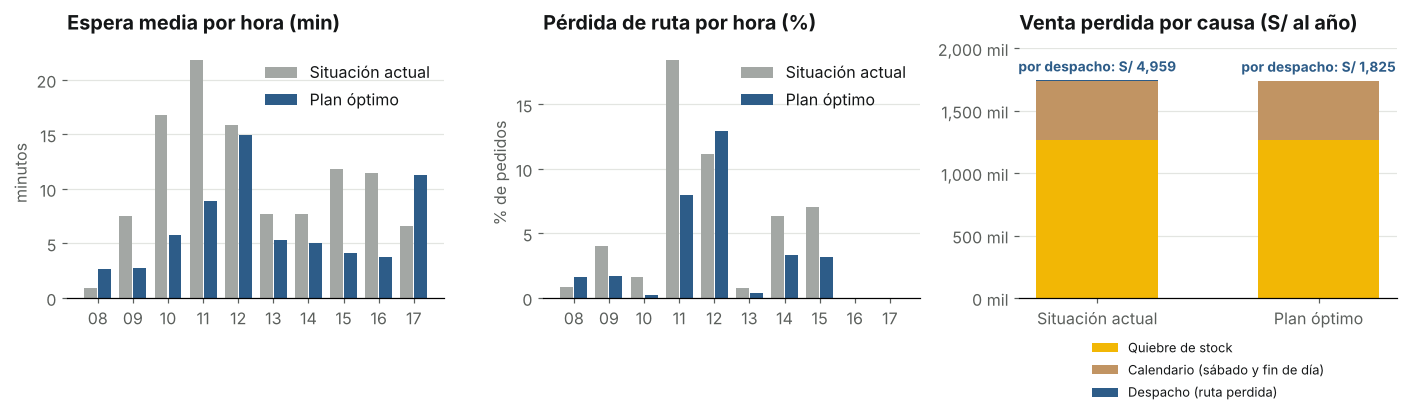

In [14]:
sim_opt = pd.concat([simular_anio(PLAN_OPTIMO, seed=s) for s in range(R)])
g_act, g_opt = sim_actual.groupby("hora"), sim_opt.groupby("hora")
perdida_h_act, perdida_h_opt = 100 * g_act["perdio_ruta"].mean(), 100 * g_opt["perdio_ruta"].mean()

fig, ax = plt.subplots(1, 3, figsize=(13, 4.0))
barras_por_hora(ax[0], {"Situación actual": (g_act["espera"].mean(), COLOR["actual"]), "Plan óptimo": (g_opt["espera"].mean(), COLOR["plan"])},
                "Espera media por hora (min)", "minutos")
barras_por_hora(ax[1], {"Situación actual": (perdida_h_act, COLOR["actual"]), "Plan óptimo": (perdida_h_opt, COLOR["plan"])},
                "Pérdida de ruta por hora (%)", "% de pedidos")
for a in ax[:2]: a.set_xticks(x, [e[:2] for e in etiquetas])

causas_t = ["quiebre", "calendario", "despacho"]
ancho = 0.55
for i, (nombre, r_) in enumerate(reps.items()):
    r_m = r_.mean()
    base_ = 0
    for c_, col in zip(causas_t, ["  por quiebre (S/)", "  por calendario (S/)", "  por despacho (S/)"]):
        ax[2].bar(i, r_m[col], bottom=base_, width=ancho, color=COLOR_CAUSA[c_], label=etiquetas_g[c_] if i == 0 else None)
        base_ += r_m[col]
for i, r_ in enumerate(reps.values()):
    r_m = r_.mean()
    ax[2].annotate(f"por despacho: {soles(r_m['  por despacho (S/)'])}", (i, r_m["Venta perdida (S/)"]), textcoords="offset points", xytext=(0, 6),
                   ha="center", fontsize=9, color=COLOR["plan"], fontweight="bold")
ax[2].set_ylim(0, reps["Actual"].mean()["Venta perdida (S/)"] * 1.15)
ax[2].set_xticks([0, 1], ["Situación actual", "Plan óptimo"]); ax[2].yaxis.set_major_formatter(k_soles)
ax[2].set_title("Venta perdida por causa (S/ al año)"); ax[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8.5)
plt.tight_layout(); plt.show()

In [15]:
# Lo que cambia con el plan, valorado: ¿se paga con la venta que recupera?
act, opt = reps["Actual"].mean(), reps["Óptimo"].mean()
costo_personal = lambda r: r["Planilla anual (S/)"] + r["Costo horas extra (S/)"]
inversion = costo_personal(opt) - costo_personal(act)
recuperado = act["  por despacho (S/)"] - opt["  por despacho (S/)"]
beneficio = recuperado * MARGEN - inversion

print("=== PLAN ÓPTIMO FRENTE A LA SITUACIÓN ACTUAL (según simulación) ===")
print(f"Espera media:                  {act['Espera media (min)']:.1f} min -> {opt['Espera media (min)']:.1f} min")
print(f"Pérdida de ruta:               {act['Pérdida de ruta (%)']:.1f} % -> {opt['Pérdida de ruta (%)']:.1f} %")
print(f"Venta perdida por despacho:    {soles(act['  por despacho (S/)'])} -> {soles(opt['  por despacho (S/)'])}   (recupera {soles(recuperado)})")
print(f"Venta perdida total:           {soles(act['Venta perdida (S/)'])} -> {soles(opt['Venta perdida (S/)'])}")
print(f"Inversión adicional (planilla + horas extra): {soles(inversion)} al año")
print(f"Resultado neto (margen {100 * MARGEN:.0f} %): {soles(beneficio)} al año")

=== PLAN ÓPTIMO FRENTE A LA SITUACIÓN ACTUAL (según simulación) ===
Espera media:                  11.7 min -> 6.1 min
Pérdida de ruta:               5.6 % -> 3.1 %
Venta perdida por despacho:    S/ 4,959 -> S/ 1,825   (recupera S/ 3,134)
Venta perdida total:           S/ 1,741,048 -> S/ 1,737,914
Inversión adicional (planilla + horas extra): S/ 16,466 al año
Resultado neto (margen 100 %): −S/ 13,331 al año


## 9. Escenario 2 — Crecimiento de la demanda

Se mantiene fijo el plan óptimo y se incrementan todas las tasas $\lambda_h$ en el mismo porcentaje; la situación actual se simula con la misma demanda para compararla.

,Espera actual (min),Espera plan (min),Pérdida ruta actual (%),Pérdida ruta plan (%),Venta perdida despacho actual (S/),Venta perdida despacho plan (S/)
Crecimiento,,,,,,
Hoy,11.7,6.1,5.6,3.1,"4,959.3","1,825.2"
+10 %,15.6,8.2,7.4,4.0,"11,130.7","5,010.1"
+20 %,20.8,11.0,9.5,5.2,"11,442.0","3,811.4"
+30 %,27.3,14.8,12.2,6.8,"22,088.2","10,274.4"
+40 %,36.0,20.3,15.1,8.8,"28,099.4","13,184.6"
+50 %,45.2,26.7,18.1,10.9,"39,654.5","17,005.4"


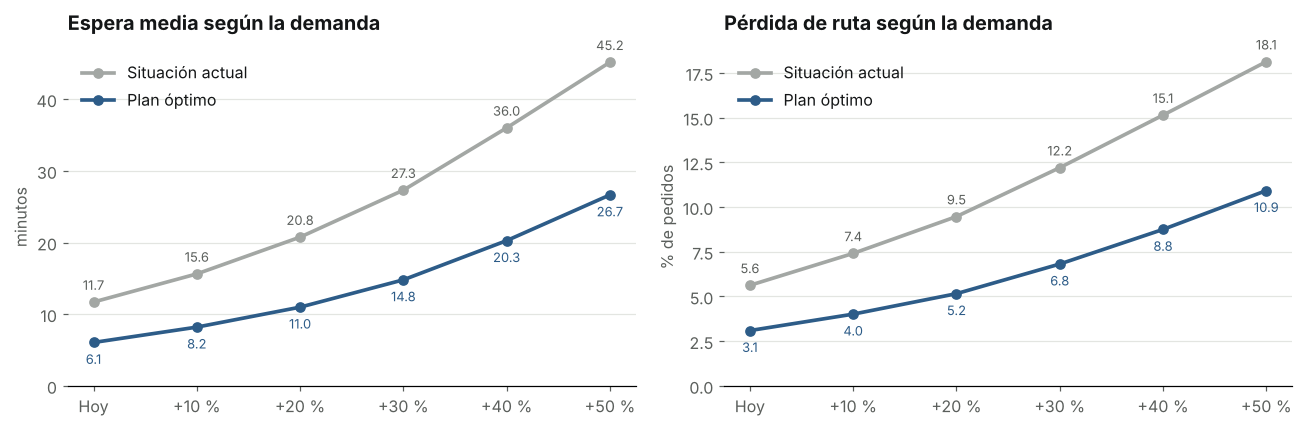

In [16]:
crec = []
for g in [0, 0.10, 0.20, 0.30, 0.40, 0.50]:
    nombre = "Hoy" if g == 0 else f"+{100 * g:.0f} %"
    ro = replicar(PLAN_OPTIMO, crecimiento=g).mean()
    ra = replicar(PLAN_ACTUAL, crecimiento=g).mean()
    crec.append({"Crecimiento": nombre, "Espera actual (min)": ra["Espera media (min)"], "Espera plan (min)": ro["Espera media (min)"],
                 "Pérdida ruta actual (%)": ra["Pérdida de ruta (%)"], "Pérdida ruta plan (%)": ro["Pérdida de ruta (%)"],
                 "Venta perdida despacho actual (S/)": ra["  por despacho (S/)"], "Venta perdida despacho plan (S/)": ro["  por despacho (S/)"]})
crec = pd.DataFrame(crec).set_index("Crecimiento")
display(crec.style.format("{:,.1f}"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.0))
for a, (c_act, c_pl, titulo, ylab) in zip(ax, [("Espera actual (min)", "Espera plan (min)", "Espera media según la demanda", "minutos"),
                                               ("Pérdida ruta actual (%)", "Pérdida ruta plan (%)", "Pérdida de ruta según la demanda", "% de pedidos")]):
    a.plot(crec.index, crec[c_act], marker="o", lw=2.4, color=COLOR["actual"], label="Situación actual")
    a.plot(crec.index, crec[c_pl], marker="o", lw=2.4, color=COLOR["plan"], label="Plan óptimo")
    for i, (va, vp) in enumerate(zip(crec[c_act], crec[c_pl])):
        a.annotate(f"{va:.1f}", (i, va), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5, color=COLOR["tinta2"])
        a.annotate(f"{vp:.1f}", (i, vp), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8.5, color=COLOR["plan"])
    a.set_title(titulo); a.set_ylabel(ylab); a.set_ylim(bottom=0); a.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 10. Escenario 3 — Ausentismo

Cada trabajador falta un día con probabilidad dada (independiente). No se reemplaza al ausente.

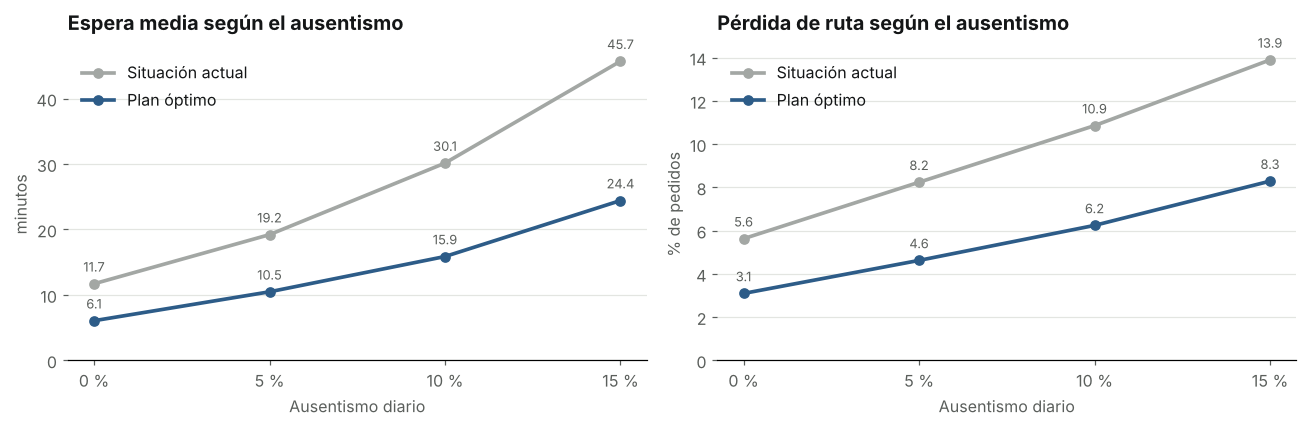

In [17]:
aus = []
for a in [0, 0.05, 0.10, 0.15]:
    for nombre, plan in [("Actual", PLAN_ACTUAL), ("Óptimo", PLAN_OPTIMO)]:
        r = replicar(plan, ausentismo=a).mean()
        aus.append({"Ausentismo (%)": round(100 * a), "Plan": nombre, **r})
aus = pd.DataFrame(aus)
display(aus.pivot(index="Ausentismo (%)", columns="Plan", values=["Espera media (min)", "Pérdida de ruta (%)", "  por despacho (S/)", "Horas extra (h/año)"])
        .style.format("{:,.1f}"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.0))
for a_, (col, titulo, ylab) in zip(ax, [("Espera media (min)", "Espera media según el ausentismo", "minutos"),
                                        ("Pérdida de ruta (%)", "Pérdida de ruta según el ausentismo", "% de pedidos")]):
    for nombre, color, etiqueta in [("Actual", COLOR["actual"], "Situación actual"), ("Óptimo", COLOR["plan"], "Plan óptimo")]:
        d = aus[aus["Plan"] == nombre]
        a_.plot(d["Ausentismo (%)"], d[col], marker="o", lw=2.4, color=color, label=etiqueta)
        for xv, yv in zip(d["Ausentismo (%)"], d[col]):
            a_.annotate(f"{yv:.1f}", (xv, yv), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5, color=COLOR["tinta2"])
    a_.set_xticks([0, 5, 10, 15], ["0 %", "5 %", "10 %", "15 %"]); a_.set_title(titulo); a_.set_xlabel("Ausentismo diario"); a_.set_ylabel(ylab)
    a_.set_ylim(bottom=0); a_.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 11. Escenario 4 — Sensibilidad del $\rho$ objetivo y margen bruto

Para cada $\rho$ objetivo se recalcula $D_h$, se **re-optimiza el MILP** (`optimizar`, el mismo modelo de la Parte I) y se simula el plan resultante. Se compara con la situación actual. El mejor plan es el que minimiza **planilla + horas extra + margen perdido**:

$$\text{Costo total} = \text{Planilla} + \text{Horas extra} + \text{margen} \times \text{Venta perdida}$$

El margen bruto no cambia la operación simulada, así que basta con revalorar los resultados.

,Plan,Personas,Espera media (min),Pérdida de ruta (%),por despacho (S/),Horas extra (h/año),Planilla anual (S/),Costo total (S/)
rho,,,,,,,,
Actual,"3 fijos, 08–18 h",3,11.7,5.6,"4,959.3",225.0,"49,446.0","1,791,695.5"
0.50,"FT-1:2, FT-2:2, FT-3:2, PT-3:1",7,0.5,0.2,0.0,172.2,"107,133.1","1,844,141.3"
0.55,"FT-2:4, FT-3:2, PT-3:1",7,0.7,0.1,0.0,172.2,"107,133.1","1,844,141.3"
0.60,"FT-2:3, FT-3:2, PT-3:1",6,1.4,0.4,0.0,172.5,"90,651.1","1,827,660.8"
0.65,"FT-1:2, FT-2:1, FT-3:2, PT-3:1",6,1.4,0.8,0.0,172.5,"90,651.1","1,827,660.8"
0.70,"FT-1:1, FT-2:2, FT-3:1, PT-2:1, PT-3:1",6,2.1,0.8,"1,336.5",206.8,"82,410.2","1,820,939.4"
0.75,"FT-1:2, FT-3:1, PT-1:1, PT-3:1",5,6.1,3.1,"1,825.2",221.9,"65,928.2","1,805,026.9"
0.80,"FT-1:2, FT-3:1, PT-1:1, PT-3:1",5,6.1,3.1,"1,825.2",221.9,"65,928.2","1,805,026.9"
0.85,"FT-1:2, FT-3:1, PT-1:1, PT-3:1",5,6.1,3.1,"1,825.2",221.9,"65,928.2","1,805,026.9"


Margen bruto,Mejor opción,Plan,Costo total (S/),Ahorro vs. situación actual (S/)
10 %,Actual,"3 fijos, 08–18 h","224,752",0
20 %,Actual,"3 fijos, 08–18 h","398,857",0
30 %,Actual,"3 fijos, 08–18 h","572,962",0
40 %,Actual,"3 fijos, 08–18 h","747,067",0
50 %,Actual,"3 fijos, 08–18 h","921,171",0
75 %,Actual,"3 fijos, 08–18 h","1,356,433",0
100 %,Actual,"3 fijos, 08–18 h","1,791,695",0


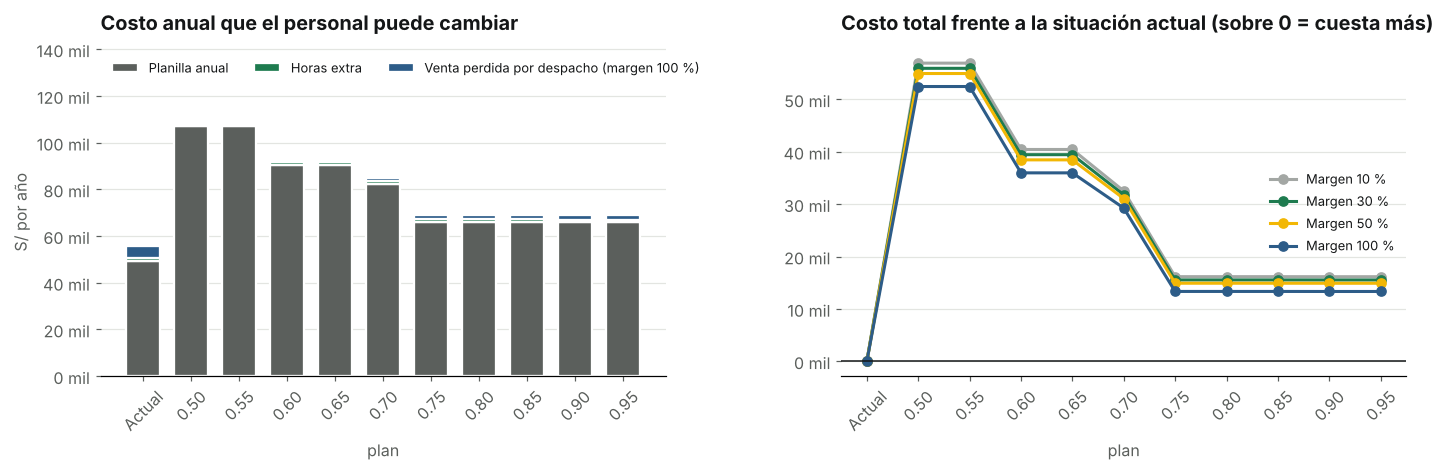

In [18]:
sens = []
for rho_obj in [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]:
    plan = optimizar(rho_obj)
    r = replicar(plan).mean()
    sens.append({"rho": f"{rho_obj:.2f}", "Plan": ", ".join(f"{t}:{n}" for t, n in plan.items()), "Personas": sum(plan.values()), **r})
r_act = replicar(PLAN_ACTUAL).mean()
sens.insert(0, {"rho": "Actual", "Plan": "3 fijos, 08–18 h", "Personas": C_ACTUAL, **r_act})
sens = pd.DataFrame(sens).set_index("rho")
columnas = ["Espera media (min)", "Pérdida de ruta (%)", "  por despacho (S/)", "Horas extra (h/año)", "Planilla anual (S/)", "Costo total (S/)"]
display(sens[["Plan", "Personas", *columnas]].style.format({c: "{:,.1f}" for c in columnas}))

margenes = [0.10, 0.20, 0.30, 0.40, 0.50, 0.75, 1.00]
costo_por_margen = pd.DataFrame({m: sens["Planilla anual (S/)"] + sens["Costo horas extra (S/)"] + m * sens["Venta perdida (S/)"] for m in margenes})
mejor_plan = costo_por_margen.idxmin()
decision = pd.DataFrame({"Margen bruto": [f"{100 * m:.0f} %" for m in margenes], "Mejor opción": mejor_plan.values,
                         "Plan": [sens.loc[r, "Plan"] for r in mejor_plan],
                         "Costo total (S/)": costo_por_margen.min().values,
                         "Ahorro vs. situación actual (S/)": (costo_por_margen.loc["Actual"] - costo_por_margen.min()).values})
display(decision.style.format({"Costo total (S/)": "{:,.0f}", "Ahorro vs. situación actual (S/)": "{:,.0f}"}).hide(axis="index"))

# La venta perdida por quiebre y por calendario no cambia con el personal: el gráfico muestra solo lo que sí cambia
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
x_rho = list(sens.index)
base_y = np.zeros(len(sens))
for col, color, etiqueta, f in [("Planilla anual (S/)", COLOR["tinta2"], "Planilla anual", 1), ("Costo horas extra (S/)", COLOR["ok"], "Horas extra", 1),
                                ("  por despacho (S/)", COLOR["plan"], f"Venta perdida por despacho (margen {100 * MARGEN:.0f} %)", MARGEN)]:
    ax[0].bar(x_rho, f * sens[col], bottom=base_y, color=color, label=etiqueta, width=0.7, edgecolor="white", linewidth=1.5)
    base_y = base_y + f * sens[col].to_numpy()
ax[0].set_ylim(0, base_y.max() * 1.3); ax[0].yaxis.set_major_formatter(k_soles); ax[0].legend(loc="upper left", ncol=3, fontsize=8.5)
ax[0].set_title("Costo anual que el personal puede cambiar"); ax[0].set_xlabel("plan"); ax[0].set_ylabel("S/ por año")
ax[0].tick_params(axis="x", labelrotation=45)
for m, color in zip([0.10, 0.30, 0.50, 1.00], [COLOR["actual"], COLOR["ok"], COLOR["aviso"], COLOR["plan"]]):
    y = costo_por_margen[m] - costo_por_margen.loc["Actual", m]
    ax[1].plot(x_rho, y, marker="o", lw=2, color=color, label=f"Margen {100 * m:.0f} %")
ax[1].axhline(0, color=COLOR["tinta"], lw=1); ax[1].yaxis.set_major_formatter(k_soles); ax[1].tick_params(axis="x", labelrotation=45)
ax[1].set_title("Costo total frente a la situación actual (sobre 0 = cuesta más)"); ax[1].set_xlabel("plan")
ax[1].legend(loc="center right", ncol=1, fontsize=8.5)
plt.tight_layout(); plt.show()

## 12. Escenario 5 — ¿Personal o quiebres de stock?

La venta perdida se concentra en los quiebres de stock. Se compara cuánto vale cada palanca: el plan de personal del MILP frente a reducir los quiebres un 25 %, un 50 %, y ambas a la vez.

,Venta perdida (S/),Planilla + horas extra (S/),Costo total (S/),Ahorro vs. actual (S/)
Opción,,,,
Situación actual,"1,741,048","50,647","1,791,695",0
Plan MILP (ρ = 0.85),"1,737,914","67,113","1,805,027","-13,331"
−25 % de quiebres,"1,439,832","50,684","1,490,516","301,180"
−50 % de quiebres,"1,134,859","50,727","1,185,586","606,110"
Plan MILP + −50 % de quiebres,"1,130,484","67,172","1,197,656","594,039"


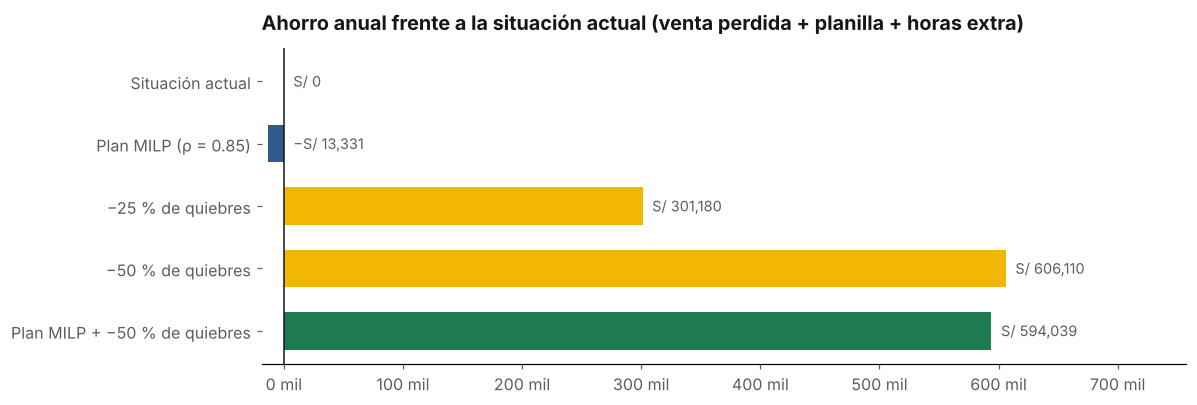

In [19]:
palancas = []
for nombre, plan, qf in [("Situación actual", PLAN_ACTUAL, 1.0), ("Plan MILP (ρ = 0.85)", PLAN_OPTIMO, 1.0),
                         ("−25 % de quiebres", PLAN_ACTUAL, 0.75), ("−50 % de quiebres", PLAN_ACTUAL, 0.50),
                         ("Plan MILP + −50 % de quiebres", PLAN_OPTIMO, 0.50)]:
    r = replicar(plan, q_quiebre=qf).mean()
    palancas.append({"Opción": nombre, "Venta perdida (S/)": r["Venta perdida (S/)"], "Planilla + horas extra (S/)": costo_personal(r), "Costo total (S/)": r["Costo total (S/)"]})
palancas = pd.DataFrame(palancas).set_index("Opción")
palancas["Ahorro vs. actual (S/)"] = palancas.loc["Situación actual", "Costo total (S/)"] - palancas["Costo total (S/)"]
display(palancas.style.format("{:,.0f}"))

fig, ax = plt.subplots(figsize=(11, 3.8))
colores_p = [COLOR["actual"], COLOR["plan"], COLOR["aviso"], COLOR["aviso"], COLOR["ok"]]
barras = ax.barh(palancas.index[::-1], palancas["Ahorro vs. actual (S/)"][::-1], color=colores_p[::-1], height=0.6)
for y_, v in enumerate(palancas["Ahorro vs. actual (S/)"][::-1]):
    ax.text(max(v, 0) + 8000, y_, soles(v), va="center", fontsize=9.5, color=COLOR["tinta2"])
ax.axvline(0, color=COLOR["tinta"], lw=1); ax.xaxis.set_major_formatter(k_soles); ax.grid(axis="y", visible=False)
ax.set_xlim(min(0, palancas["Ahorro vs. actual (S/)"].min() * 1.4), palancas["Ahorro vs. actual (S/)"].max() * 1.25)
ax.set_title("Ahorro anual frente a la situación actual (venta perdida + planilla + horas extra)")
plt.tight_layout(); plt.show()

## 13. Conclusiones

Las cifras de esta sección se calculan con los resultados de los capítulos anteriores: si se cambia un parámetro y se vuelve a ejecutar, el texto se actualiza.

In [20]:
cob_opt = personal_por_hora(PLAN_OPTIMO, TURNOS_SIM)
horas_debiles = [h for h in HORAS if perdida_h_opt[h] > 8]
g_ = lambda nombre: crec.loc[nombre]
a10 = aus[aus["Ausentismo (%)"] == 10].set_index("Plan")
a15 = aus[aus["Ausentismo (%)"] == 15].set_index("Plan")
rho_mejor = [r for r in sens.index if r != "Actual"]
mejor_mg = {m: mejor_plan[m] for m in margenes}
grupos = []
for m, v in mejor_mg.items():
    if grupos and grupos[-1][0] == v: grupos[-1][1].append(m)
    else: grupos.append([v, [m]])
nombre_opcion = lambda v: "mantener la situación actual" if v == "Actual" else f"el plan de ρ = {v}"
if len(grupos) == 1:
    frases_margen = f"con cualquier margen bruto (de {100 * margenes[0]:.0f} % a {100 * margenes[-1]:.0f} %), la mejor opción es **{nombre_opcion(grupos[0][0])}**"
else:
    frases_margen = "; ".join(f"con margen de {100 * ms[0]:.0f} % a {100 * ms[-1]:.0f} %: **{nombre_opcion(v)}**" for v, ms in grupos)
paga = beneficio > 0

debil_txt = ""
for h in horas_debiles:
    motivo = ("con un solo despachador, un pedido que llega con él ocupado espera un servicio completo" if cob_opt[h] == 1 else
              f"la capacidad es de {cob_opt[h]} despachadores en esa hora")
    debil_txt += f"* **{h}:00 h** ({cob_opt[h]} despachador{'es' if cob_opt[h] > 1 else ''}): pérdida de ruta de ≈ {perdida_h_opt[h]:.0f} % — {motivo}.\n"
if not debil_txt:
    debil_txt = "* Ninguna hora supera el 8 % de pérdida de ruta con el plan óptimo.\n"

display(Markdown(f'''
**Los datos de 2025 cambian la pregunta.** Con 3 despachadores ninguna hora llega a $\\rho = 1$ (el máximo es {rho.max():.2f}), aunque a las {', '.join(sobre)} se supera el objetivo de 0.85. De {soles(total_perdida)} de venta perdida, solo {soles(VENTA_DESPACHO_2025)} ({100 * VENTA_DESPACHO_2025 / total_perdida:.1f} %) se debe a pedidos que perdieron su camión; el {100 * por_grupo['quiebre'] / total_perdida:.0f} % viene de quiebres de stock y el {100 * por_grupo['calendario'] / total_perdida:.0f} % del calendario de camiones.

**Validación.** El simulador, alimentado con los 8 012 pedidos reales, reproduce las esperas y las rutas perdidas del archivo (capítulo 7), y con pedidos aleatorios reproduce los totales de 2025 y el perfil por hora (espera media {mid('Espera media (min)'):.1f} min vs {PAR['espera_media']:.1f}; pérdida de ruta {mid('Pérdida de ruta (%)'):.1f} % vs {PAR['perdio_ruta_pct']:.1f} %).

**1. Actual vs. óptimo.** El plan MILP ({soles(inversion)} más al año entre planilla y horas extra) baja la espera media de {act['Espera media (min)']:.1f} a {opt['Espera media (min)']:.1f} min y la pérdida de ruta de {act['Pérdida de ruta (%)']:.1f} % a {opt['Pérdida de ruta (%)']:.1f} %. Pero recupera solo {soles(recuperado)} de venta al año: {'el plan se paga' if paga else '**el plan no se paga con la venta que recupera**'} (resultado neto {soles(beneficio)} al año a precio de venta). El análisis analítico del capítulo 5, que atribuye al despacho toda la venta perdida, sobreestima el beneficio.

**Puntos débiles del plan** (el MILP no los ve porque solo mira $\\rho_h$):

{debil_txt}
**2. Crecimiento.** Con +30 % de demanda la espera media del plan es {g_('+30 %')['Espera plan (min)']:.1f} min (la situación actual, {g_('+30 %')['Espera actual (min)']:.1f}); con +50 %, {g_('+50 %')['Espera plan (min)']:.1f} min frente a {g_('+50 %')['Espera actual (min)']:.1f}.

**3. Ausentismo.** Con 10 % de ausentismo diario la espera media del plan sube a {a10.loc['Óptimo', 'Espera media (min)']:.1f} min (situación actual: {a10.loc['Actual', 'Espera media (min)']:.1f}) y con 15 %, a {a15.loc['Óptimo', 'Espera media (min)']:.1f} min ({a15.loc['Actual', 'Espera media (min)']:.1f}).

**4. Horas extra.** Despachar lo pendiente después de las 18:00 cuesta poco: ≈ {act['Horas extra (h/año)']:.0f} h/año en la situación actual y {opt['Horas extra (h/año)']:.0f} h/año con el plan óptimo (≈ {soles(opt['Costo horas extra (S/)'])} al año).

**5. $\\rho$ objetivo y margen bruto.** Ningún plan del MILP supera a la situación actual en costo total: {frases_margen}. La razón es que lo único que el personal puede recuperar es la venta ligada al despacho, y es una fracción mínima de la venta perdida.

**6. ¿Dónde está el dinero?** Reducir los quiebres de stock un 25 % ahorraría ≈ {soles(palancas.loc['−25 % de quiebres', 'Ahorro vs. actual (S/)'])} al año y un 50 %, ≈ {soles(palancas.loc['−50 % de quiebres', 'Ahorro vs. actual (S/)'])}; el plan de personal, {soles(palancas.loc['Plan MILP (ρ = 0.85)', 'Ahorro vs. actual (S/)'])} (cuesta más de lo que recupera).

**Limitaciones.** Preparación gamma independiente del tamaño del pedido, 3 despachadores fijos como situación actual y sin almuerzos (los datos de 2025 no muestran caídas de capacidad al mediodía; en {PAR['dias_refuerzo']} de {PAR['dias']} días hubo un cuarto despachador), días independientes (lo pendiente no pasa al día siguiente) y sin feriados. La probabilidad de perder al cliente tras una entrega tardía (≈ {100 * PAR['p_cliente_perdido']:.0f} %) se estima con pocos casos ({PAR['causas']['Cliente perdido tras perder la ruta (despacho)'][0]} clientes perdidos tras perder la ruta en 2025). Solo se pagan como extra las horas posteriores a las 18:00, con 25 % de sobretasa (desde la tercera hora del día la ley exige 35 %). El valor de una entrega tardía para el cliente más allá de la venta perdida no está en los datos y no se valora.
'''))


**Los datos de 2025 cambian la pregunta.** Con 3 despachadores ninguna hora llega a $\rho = 1$ (el máximo es 0.95), aunque a las 09:00, 10:00, 15:00 se supera el objetivo de 0.85. De S/ 1,820,721 de venta perdida, solo S/ 9,426 (0.5 %) se debe a pedidos que perdieron su camión; el 72 % viene de quiebres de stock y el 28 % del calendario de camiones.

**Validación.** El simulador, alimentado con los 8 012 pedidos reales, reproduce las esperas y las rutas perdidas del archivo (capítulo 7), y con pedidos aleatorios reproduce los totales de 2025 y el perfil por hora (espera media 11.7 min vs 11.4; pérdida de ruta 5.6 % vs 5.3 %).

**1. Actual vs. óptimo.** El plan MILP (S/ 16,466 más al año entre planilla y horas extra) baja la espera media de 11.7 a 6.1 min y la pérdida de ruta de 5.6 % a 3.1 %. Pero recupera solo S/ 3,134 de venta al año: **el plan no se paga con la venta que recupera** (resultado neto −S/ 13,331 al año a precio de venta). El análisis analítico del capítulo 5, que atribuye al despacho toda la venta perdida, sobreestima el beneficio.

**Puntos débiles del plan** (el MILP no los ve porque solo mira $\rho_h$):

* **12:00 h** (2 despachadores): pérdida de ruta de ≈ 13 % — la capacidad es de 2 despachadores en esa hora.

**2. Crecimiento.** Con +30 % de demanda la espera media del plan es 14.8 min (la situación actual, 27.3); con +50 %, 26.7 min frente a 45.2.

**3. Ausentismo.** Con 10 % de ausentismo diario la espera media del plan sube a 15.9 min (situación actual: 30.1) y con 15 %, a 24.4 min (45.7).

**4. Horas extra.** Despachar lo pendiente después de las 18:00 cuesta poco: ≈ 225 h/año en la situación actual y 222 h/año con el plan óptimo (≈ S/ 1,185 al año).

**5. $\rho$ objetivo y margen bruto.** Ningún plan del MILP supera a la situación actual en costo total: con cualquier margen bruto (de 10 % a 100 %), la mejor opción es **mantener la situación actual**. La razón es que lo único que el personal puede recuperar es la venta ligada al despacho, y es una fracción mínima de la venta perdida.

**6. ¿Dónde está el dinero?** Reducir los quiebres de stock un 25 % ahorraría ≈ S/ 301,180 al año y un 50 %, ≈ S/ 606,110; el plan de personal, −S/ 13,331 (cuesta más de lo que recupera).

**Limitaciones.** Preparación gamma independiente del tamaño del pedido, 3 despachadores fijos como situación actual y sin almuerzos (los datos de 2025 no muestran caídas de capacidad al mediodía; en 24 de 299 días hubo un cuarto despachador), días independientes (lo pendiente no pasa al día siguiente) y sin feriados. La probabilidad de perder al cliente tras una entrega tardía (≈ 16 %) se estima con pocos casos (2 clientes perdidos tras perder la ruta en 2025). Solo se pagan como extra las horas posteriores a las 18:00, con 25 % de sobretasa (desde la tercera hora del día la ley exige 35 %). El valor de una entrega tardía para el cliente más allá de la venta perdida no está en los datos y no se valora.


## Anexo — Parámetros que usa el simulador web

El simulador interactivo (`Simulacion/web/`) reimplementa este mismo modelo en JavaScript. Estos son los valores que debe tener y que `node verificar.js` comprueba contra el notebook.

In [21]:
anexo = []
for rho_obj in [0.85, 0.70, 0.50]:                       # los planes distintos que ofrece el simulador web
    plan_nb = optimizar(rho_obj)
    anexo.append({"rho": rho_obj, "Plan (MILP)": ", ".join(f"{t} ×{n}" for t, n in plan_nb.items()), "Planilla (S/ mes)": costo_mensual(plan_nb),
                  "Personal por hora": " ".join(str(v) for v in personal_por_hora(plan_nb).values())})
display(pd.DataFrame(anexo).style.hide(axis="index").format({"Planilla (S/ mes)": "{:,.2f}", "rho": "{:.2f}"}))
print(f"D_h (rho 0.85): {list(req_h.values())} | ticket = S/ {TICKET:,.2f} | hora extra = S/ {COSTO_HORA_EXTRA:.2f} | {DIAS} días | {R} réplicas")
print(f"Gamma(k = {K_SERVICIO:.2f}, media {MU_MIN}) | k monto = {K_MONTO:.2f} | factor día = {FACTOR_DIA}")

rho,Plan (MILP),Planilla (S/ mes),Personal por hora
0.85,"FT-1 ×2, FT-3 ×1, PT-1 ×1, PT-3 ×1","5,494.02",2 4 4 4 2 3 3 4 4 2
0.70,"FT-1 ×1, FT-2 ×2, FT-3 ×1, PT-2 ×1, PT-3 ×1","6,867.52",3 4 5 5 4 3 4 5 5 2
0.50,"FT-1 ×2, FT-2 ×2, FT-3 ×2, PT-3 ×1","8,927.76",4 6 6 6 4 4 5 7 7 3


D_h (rho 0.85): [2, 4, 4, 3, 2, 2, 3, 4, 3, 2] | ticket = S/ 2,475.00 | hora extra = S/ 5.34 | 299 días | 10 réplicas
Gamma(k = 6.19, media 44.5) | k monto = 3.06 | factor día = [1.116, 0.962, 0.997, 1.004, 1.096, 0.819]
